# The Binomial Distribution

For $0\leq p \leq 1$ and a natural number $n$ the *binomial distribution* is given by 

$$
P(X=x)=
\begin{cases}
\binom{n}{x}p^x(1-p)^{n-x}, & x\in{0,1,\ldots,n},\\
0, & \text{otherwise}.
\end{cases}
$$

We write $X\sim \operatorname{Binomial}(n,p)$ or $X\sim \operatorname{Bin}(n,p)$, whenever a random variable $X$ has a Binomial distribution. 

**Remark:**
1) For $n=1$ the special case of the *Bernoulli distribution* arises. 
2) The Binomial distribution describes the probability of exactly $k$ successes in $n$ independent trials. This is a special case of Proposition 2 below, since the trials can be modeled as iid Bernoulli distributed random variables. This is intuitively clear. However, the fan of a rigorous argument might enjoy the proof below.

**Lemma 1:**
For $X\sim \operatorname{Bin}(n,p)$ the moment generating function is given by 
$
M_X(t)=((1-p)+pe^t)^n. 
$

*Proof:*
Using the binomial theorem it is straightforward to compute
\begin{align*}
M_X(t)
&=\mathbb{E}[e^{tX}]
=\sum_{k=0}^{n}e^{tk}P(X=k)
=\sum_{k=0}^{n}e^{tk}
\binom{n}{k}p^k(1-p)^{n-k}\\
&=\sum_{k=0}^{n}
\binom{n}{k}(pe^t)^k(1-p)^{n-k}
=(pe^t+(1-p))^n.
\qquad \blacksquare
\end{align*}

**Proposition 2:**
if $X_1,\dots, X_n$ are iid Binomial random variables with $X_i\sim \operatorname{Bin}(n_i,p)$, then $\sum_{i=1}^n X_i \sim \operatorname{Bin}\left(\sum_{i=1}^n n_i,p\right)$. 

*Proof:* 
Using that the $X_i$ are iid we compute for $Y:=\sum_{i=1}^n X_i$ and applying Lemma 1
\begin{align*}
    M_Y(t) 
    &= \mathbb{E}[e^{tX}]
    = \mathbb{E}\left[e^{t\sum_i X_i}\right]
    = \mathbb{E}\left[\prod_ie^{tX_i}\right]
    \overset{iid}{=} \prod_i\mathbb{E}[e^{tX_i}]\\
    &\overset{iid}{=} \prod_iM_{X_i}(t)
    = \prod_{i=1}^n (pe^t+(1-p))^{n_i}
    =(pe^t+(1-p))^{\sum_{i=1}^n n_i}.
\end{align*}
Since moment generating functions uniquely determine the distribution we obtain from Lemma 1 that $Y\sim \operatorname{Bin}\left(\sum_{i=1}^n n_i,p\right)$.  $\qquad \blacksquare$


**Proposition 3:** 
For $X\sim \operatorname{Bin}(n,p)$ we have 
1) $\mathbb{E}[X]=np$, and 
2) $\operatorname{Var}[X]=np(1-p)$. 

*Proof:*
Let $X_1,\dots,X_n$ be iid random variables with $X_i\sim \operatorname{Binomial}(1,p)$. 
Without lost of generality we assume that $X=\sum_{i=1}^n X_i$. 
We have $\mathbb{E}[X_i]= 0(p-1)+1p=p$ and $\operatorname{Var}[X_i]=\mathbb{E}[X_i^2]-p^2=0^2(1-p)+1^2p -p^2=p-p^2=p(1-p)$. 
We have
$\mathbb{E}[X]
=\sum_i \mathbb{E}[X_i] 
=np$
and the independence yields
\begin{aligned}
\operatorname{Var}[X]
=\sum_i \operatorname{Var}[X_i]
=np(1-p). \qquad\blacksquare
\end{aligned}



<!--
*Proof:*
For $x=1,\dots, n$ we have 
$$
x\binom{n}{x}
=n\frac{(n-1)!}{(x-1)!((n-1)-(x-1))!}
=n\binom{n-1}{x-1}
$$
and hence
\begin{aligned}
\mathbb{E}[X]
&=\sum_{x=0}^n x\binom{n}{x}p^x(1-p)^{n-x}
=\sum_{x=1}^n
n\binom{n-1}{x-1}p^x(1-p)^{n-x}\\
&=np\sum_{x=0}^{n-1}
\binom{n-1}{x}p^x(1-p)^{(n-1)-x}
=np(p-(1-p))^{n-1}=np.
\end{aligned}

Furthermore, for $x=2,\dots, n$ we have 
$$
x(x-1)\binom{n}{x}
= n(x-1)\binom{n-1}{x-1}
= n(n-1)\binom{n-2}{x-2}
$$

\begin{aligned}
\mathbb{E}[X(X-1)]
&=\sum_{x=0}^n x(x-1)\binom{n}{x}p^x(1-p)^{n-x}
=\sum_{x=2}^n
n(n-1)p^2\binom{n-2}{x-2}p^(x-2)(1-p)^{(n-2)-(x-2)}\\
&=n(n-1)p^2(p-(1-p))^{n-2}=n(n-1)p^2
\end{aligned}

and hence
$$
\mathbb{E}[X^2]
= \mathbb{E}[X(X-1)] + \mathbb{E}[X]
= n(n-1)p^2 + n^2p^2 = np^2.
$$
Thus,
\begin{aligned}
\operatorname{Var}[X]
&= \mathbb{E}[X(X-1)] + \mathbb{E}[X] -\mathbb{E}[X]^2
= n(n-1)p^2 +np - n^2p^2 \\
&= -np^2+np 
= np(1-p).  \qquad\blacksquare
\end{aligned}
-->

## Some Visualizations

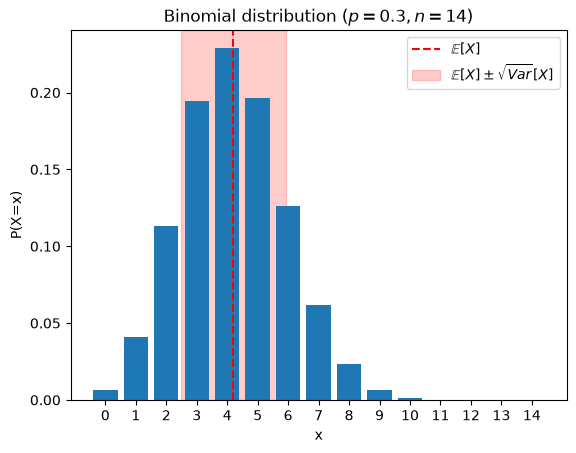

In [8]:
from math import comb, sqrt
from matplotlib import pyplot as plt

p = 0.3
n = 14

def binomial_distribution(p=0.5,n=1):
    def f(x):
        x = int(x)
        if x in range(0,n+1):
            return comb(n,x) * p**x * (1-p)**(n-x)
        else:
            return 0
    return f    


mean = n*p
std = sqrt(n*p*(1-p))
mean_label = rf'$\mathbb{{E}}[X]$'
plt.axvline(x=mean,color='red',linestyle='--',label=mean_label)
std_label = rf'$\mathbb{{E}}[X]\pm\sqrt{{Var}}[X]$'
plt.axvspan(mean - std,mean + std,color='red',alpha=0.2,label=std_label)


x_range = range(0,n+1)
f = binomial_distribution(p=p, n=n)
plt.bar(x_range, [f(x) for x in x_range])
plt.title('Binomial distribution '+rf'$(p={p},n={n})$')
plt.xlabel('x')
plt.xticks(x_range)
plt.ylabel('P(X=x)')
plt.legend()
plt.show()

## Simulation

A binomial distribution can easily be simulated with numpy.

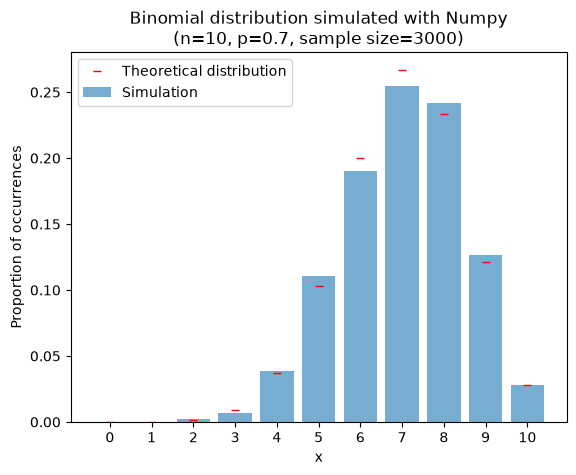

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n = 10
p = 0.7
size = 3000

rng = np.random.default_rng()
samples = rng.binomial(n=n, p=p, size=size)
k = np.arange(n + 1)

# Empirical
empirical = np.bincount(samples, minlength=n + 1) / size
plt.bar(k, empirical, label="Simulation", alpha = 0.6)

# Theoretical
theoretical = binom.pmf(k, n, p)
plt.plot(k, theoretical, "r_", label="Theoretical distribution")

plt.xlabel("x")
plt.ylabel("Proportion of occurrences")
plt.title(f"Binomial distribution simulated with Numpy\n(n={n}, p={p}, sample size={size})")
plt.xticks(k)
plt.legend()
plt.show()

With `scipy` it can be simulated as follows.

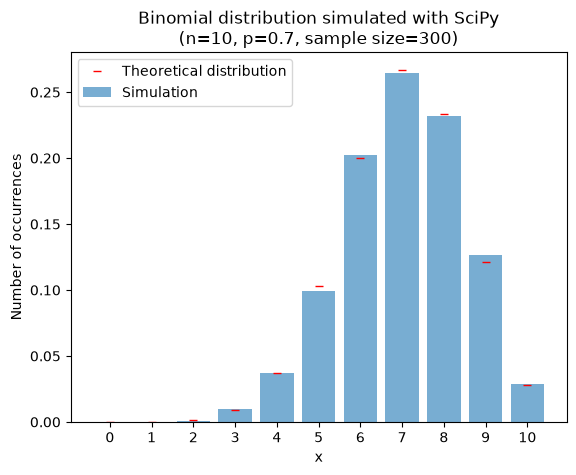

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n = 10
p = 0.7
sample_size = 5000

# Empirical
samples = binom.rvs(n, p, size=sample_size, random_state=42)
empirical = np.bincount(samples, minlength=n + 1) / sample_size
plt.bar(k, empirical, label="Simulation", alpha = 0.6)

# Theoretical
theoretical = binom.pmf(k, n, p)
plt.plot(k, theoretical, "r_", label="Theoretical distribution")

plt.xlabel("x")
plt.ylabel("Proportion of occurrences")
plt.title(f"Binomial distribution simulated with SciPy\n(n={n}, p={p}, sample size={size})")
plt.xticks(k)
plt.legend()
plt.show()